In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from datetime import datetime
import os
#from sklearn.ensemble import IsolationForest
#from sklearn.preprocessing import RobustScaler
#from sklearn.preprocessing import OneHotEncoder

In [2]:
#Lettura file dati mergiati ch4-bufale e robot, selezionando solo colonne che ci servono per questo momento.

mandria_path = './dati_bufale/merged_buffalo_sniffer_AMS_detrended.csv'
mandria = pd.read_csv(mandria_path, usecols = ['timestamp', 'CH4', 'CO2', 'Numero animale', 'milking_number', 'Ora inizio', 'Durata (mm:ss)', 'Milking_end'])

mandria['Numero animale'] = mandria['Numero animale'].apply(lambda x: int(x))
mandria['milking_number'] = mandria['milking_number'].apply(lambda x: int(x))


mandria_ch4 = mandria[['timestamp', 'CH4', 'Numero animale', 'milking_number']]

In [3]:
mandria_ch4.tail()

,timestamp,CH4,Numero animale,milking_number
583900,2024-05-29 21:57:45.243325,-244.739421,242859,1155
583901,2024-05-29 21:57:46.245400,-101.639355,242859,1155
583902,2024-05-29 21:57:47.247483,-100.239288,242859,1155
583903,2024-05-29 21:57:48.250095,-108.139222,242859,1155
583904,2024-05-29 21:57:49.252147,-116.239156,242859,1155


In [4]:
#check
mungiture = list(set(mandria_ch4['milking_number']))
print(len(mungiture))
animals = list(set(mandria_ch4['Numero animale']))
print(len(animals))

1155
36


In [5]:
mandria_ch4 = mandria_ch4[mandria_ch4['milking_number'] < 50]
print(mandria_ch4.tail())

                        timestamp        CH4  Numero animale  milking_number
44067  2024-05-16 14:35:04.720568  17.943032            1687              49
44068  2024-05-16 14:35:05.221802   6.843098            1687              49
44069  2024-05-16 14:35:05.722999  -3.756835            1687              49
44070  2024-05-16 14:35:06.224311 -26.756769            1687              49
44071  2024-05-16 14:35:06.725370 -37.656703            1687              49


In [6]:
#check
mungiture = list(set(mandria_ch4['milking_number']))
print(len(mungiture))
animals = list(set(mandria_ch4['Numero animale']))
print(len(animals))

49
35


(969, 4)
(964, 4)
Average after removal of background is:  334.24
Median after removal of background is:  206.21
1


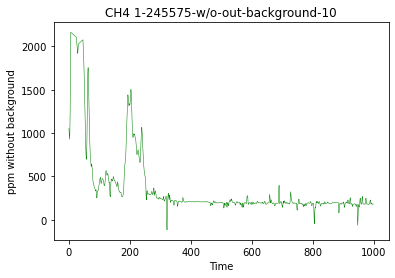

(831, 4)
(827, 4)
Average after removal of background is:  267.83
Median after removal of background is:  185.09
2


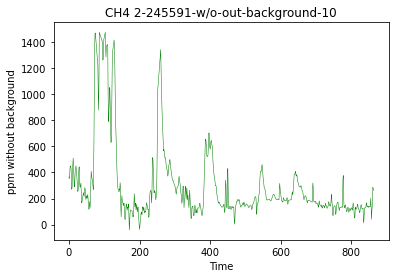

(552, 4)
(547, 4)
Average after removal of background is:  109.86
Median after removal of background is:  106.26
3


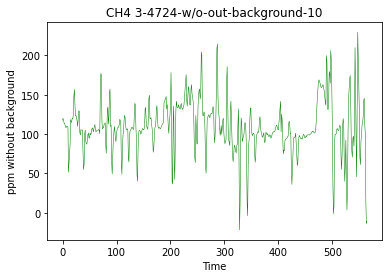

(1229, 4)
(1225, 4)
Average after removal of background is:  285.94
Median after removal of background is:  198.92
4


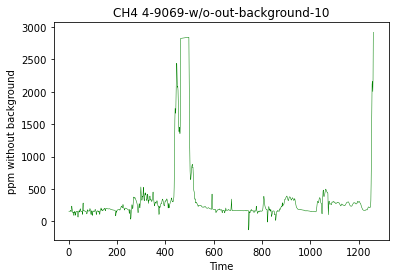

(1494, 4)
(1490, 4)
Average after removal of background is:  332.36
Median after removal of background is:  212.84
5


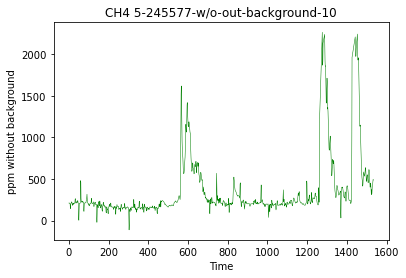

(749, 4)
(745, 4)
Average after removal of background is:  428.48
Median after removal of background is:  263.4
6


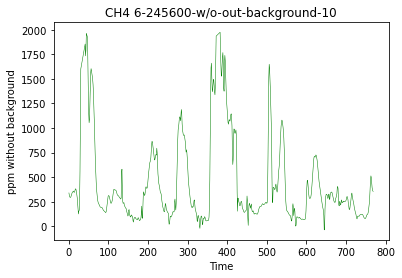

(533, 4)
(530, 4)
Average after removal of background is:  669.85
Median after removal of background is:  337.17
7


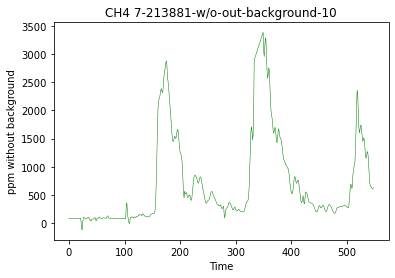

(894, 4)
(889, 4)
Average after removal of background is:  65.22
Median after removal of background is:  60.56
8


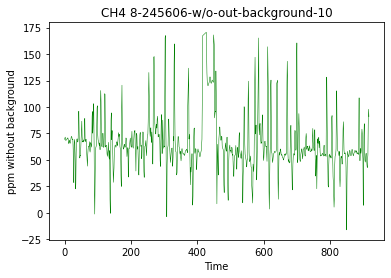

(707, 4)
(702, 4)
Average after removal of background is:  127.2
Median after removal of background is:  116.82
9


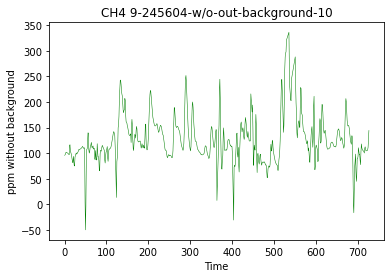

(563, 4)
(561, 4)
Average after removal of background is:  305.3
Median after removal of background is:  167.54
10


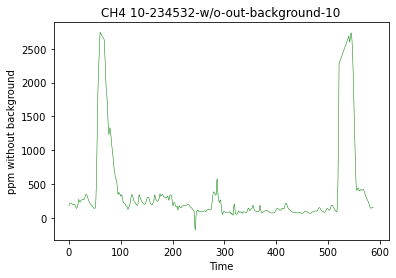

(938, 4)
(934, 4)
Average after removal of background is:  185.84
Median after removal of background is:  161.22
11


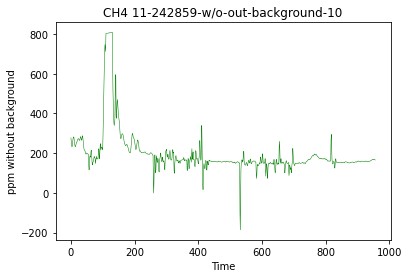

(567, 4)
(561, 4)
Average after removal of background is:  80.91
Median after removal of background is:  75.87
12


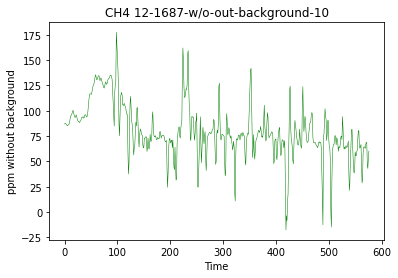

(1112, 4)
(1108, 4)
Average after removal of background is:  202.45
Median after removal of background is:  96.73
13


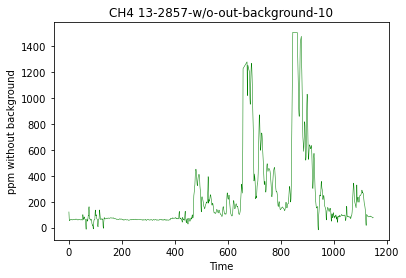

(624, 4)
(621, 4)
Average after removal of background is:  147.69
Median after removal of background is:  129.24
14


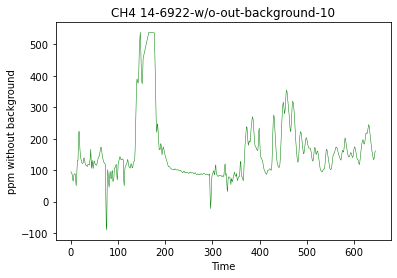

(1121, 4)
(1119, 4)
Average after removal of background is:  298.53
Median after removal of background is:  199.27
15


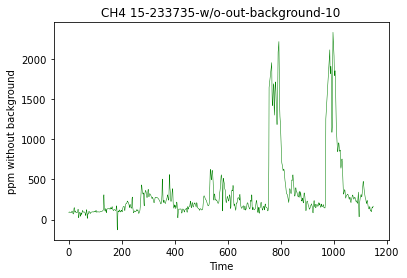

(730, 4)
(726, 4)
Average after removal of background is:  153.46
Median after removal of background is:  138.82
16


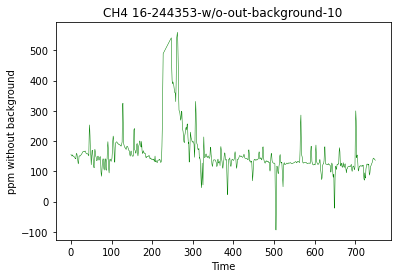

(675, 4)
(670, 4)
Average after removal of background is:  211.0
Median after removal of background is:  150.3
17


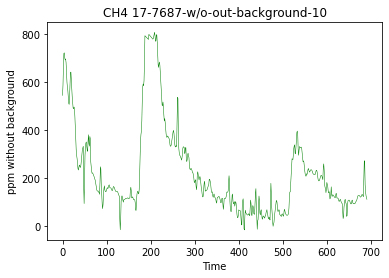

(1038, 4)
(1033, 4)
Average after removal of background is:  182.28
Median after removal of background is:  172.39
18


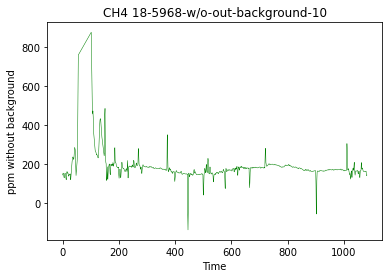

(742, 4)
(739, 4)
Average after removal of background is:  93.86
Median after removal of background is:  81.76
19


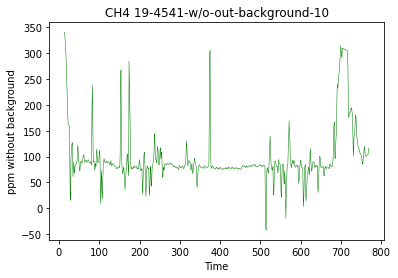

(868, 4)
(865, 4)
Average after removal of background is:  105.96
Median after removal of background is:  90.74
20


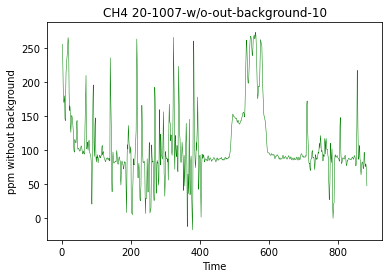

(1017, 4)
(1012, 4)
Average after removal of background is:  172.01
Median after removal of background is:  161.81
21


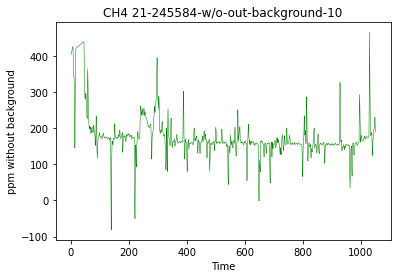

(585, 4)
(583, 4)
Average after removal of background is:  82.0
Median after removal of background is:  76.6
22


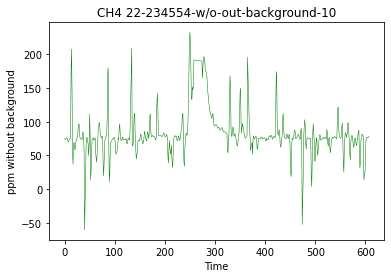

(625, 4)
(622, 4)
Average after removal of background is:  63.22
Median after removal of background is:  62.44
23


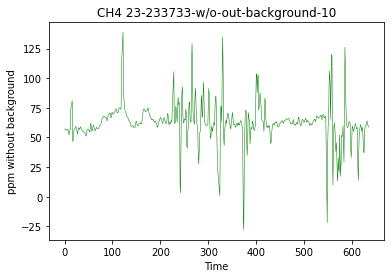

(1112, 4)
(1107, 4)
Average after removal of background is:  132.94
Median after removal of background is:  118.85
24


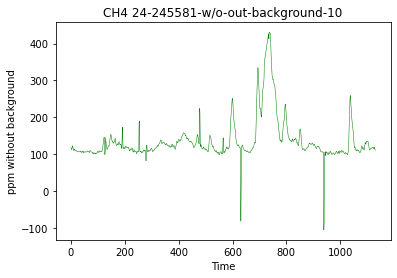

(934, 4)
(930, 4)
Average after removal of background is:  152.86
Median after removal of background is:  113.13
25


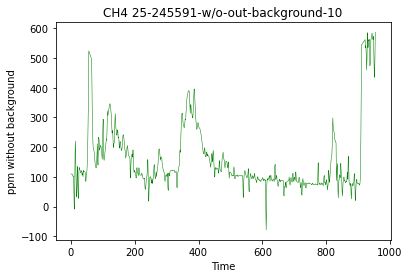

(695, 4)
(692, 4)
Average after removal of background is:  183.02
Median after removal of background is:  144.19
26


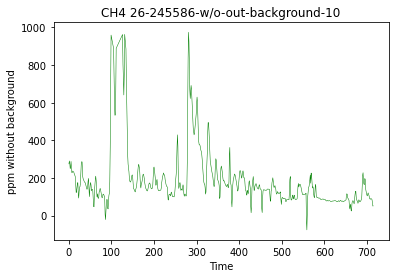

(743, 4)
(740, 4)
Average after removal of background is:  129.86
Median after removal of background is:  109.27
27


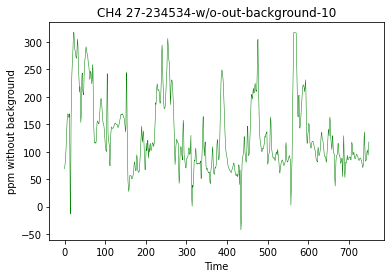

(977, 4)
(974, 4)
Average after removal of background is:  224.79
Median after removal of background is:  186.71
28


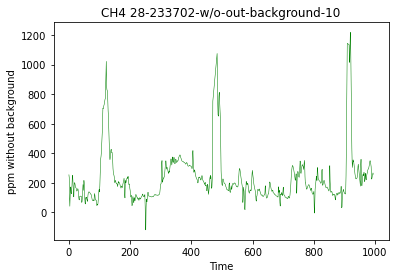

(817, 4)
(813, 4)
Average after removal of background is:  72.82
Median after removal of background is:  69.87
29


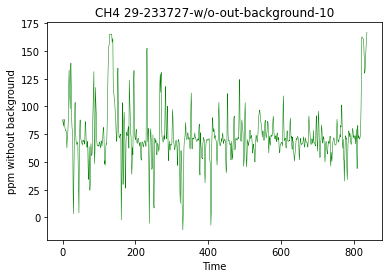

(575, 4)
(571, 4)
Average after removal of background is:  199.08
Median after removal of background is:  128.04
30


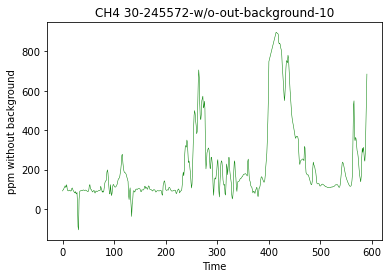

(945, 4)
(942, 4)
Average after removal of background is:  301.58
Median after removal of background is:  220.05
31


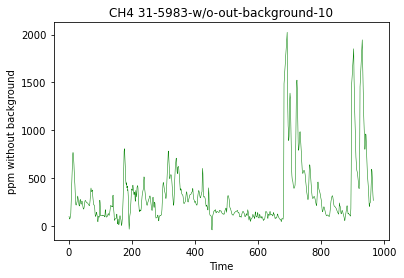

(766, 4)
(762, 4)
Average after removal of background is:  360.99
Median after removal of background is:  210.41
32


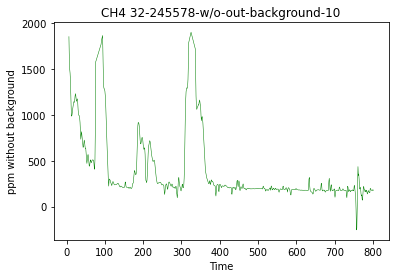

(852, 4)
(850, 4)
Average after removal of background is:  676.75
Median after removal of background is:  345.27
33


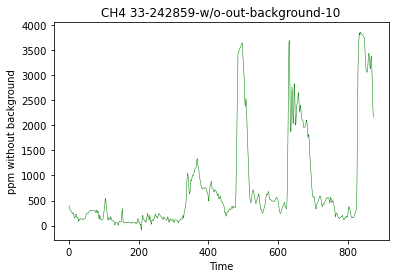

(2264, 4)
(2259, 4)
Average after removal of background is:  327.41
Median after removal of background is:  212.01
34


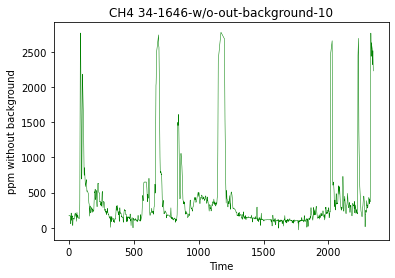

(940, 4)
(936, 4)
Average after removal of background is:  199.93
Median after removal of background is:  155.78
35


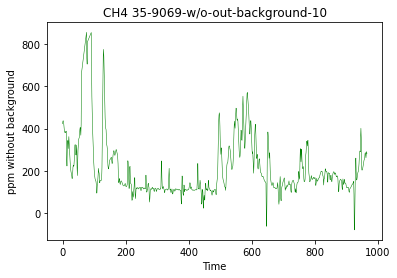

(903, 4)
(899, 4)
Average after removal of background is:  221.22
Median after removal of background is:  144.9
36


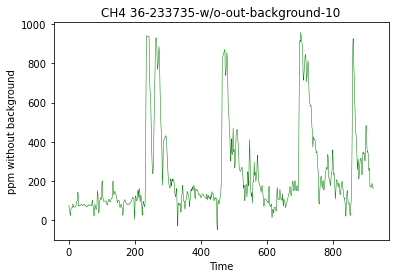

(704, 4)
(699, 4)
Average after removal of background is:  92.61
Median after removal of background is:  84.29
37


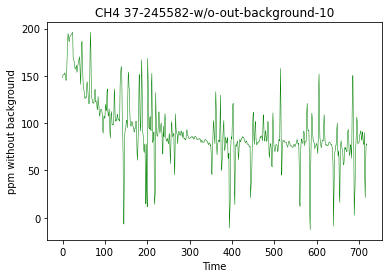

(674, 4)
(671, 4)
Average after removal of background is:  433.19
Median after removal of background is:  183.57
38


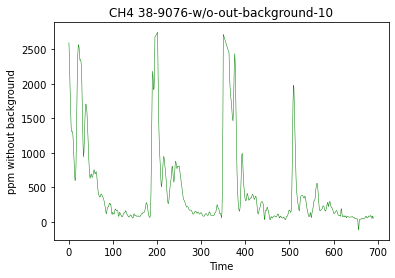

(947, 4)
(942, 4)
Average after removal of background is:  147.99
Median after removal of background is:  120.88
39


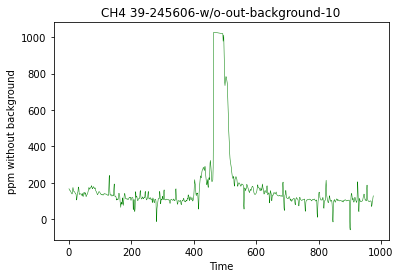

(658, 4)
(653, 4)
Average after removal of background is:  72.33
Median after removal of background is:  73.22
40


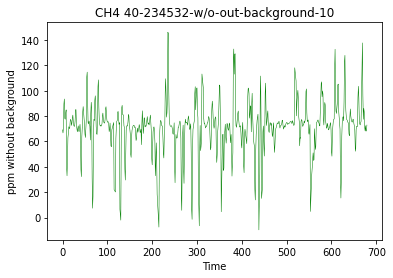

(553, 4)
(549, 4)
Average after removal of background is:  267.05
Median after removal of background is:  189.52
41


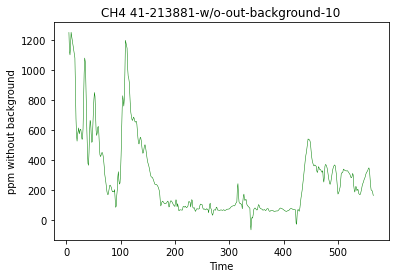

(658, 4)
(654, 4)
Average after removal of background is:  66.91
Median after removal of background is:  64.71
42


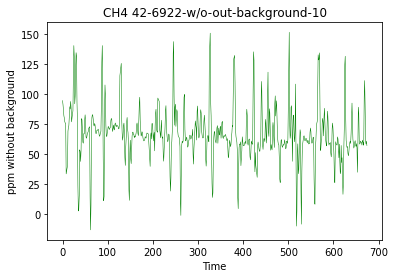

(595, 4)
(591, 4)
Average after removal of background is:  61.81
Median after removal of background is:  61.17
43


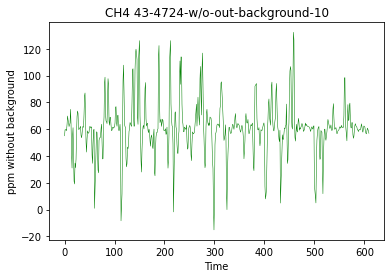

(1883, 4)
(1880, 4)
Average after removal of background is:  270.25
Median after removal of background is:  202.95
44


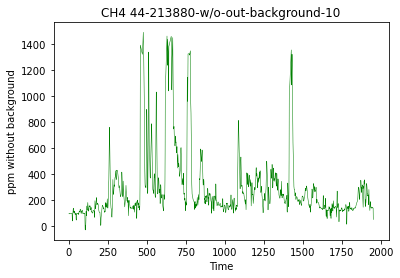

(770, 4)
(766, 4)
Average after removal of background is:  306.11
Median after removal of background is:  161.53
45


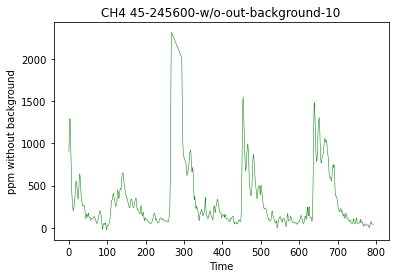

(1429, 4)
(1424, 4)
Average after removal of background is:  363.72
Median after removal of background is:  252.62
46


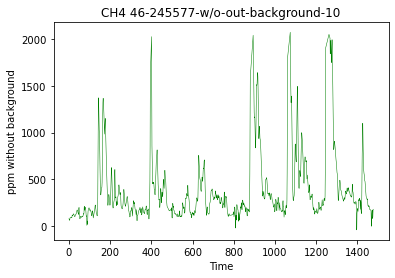

(690, 4)
(686, 4)
Average after removal of background is:  100.95
Median after removal of background is:  96.43
47


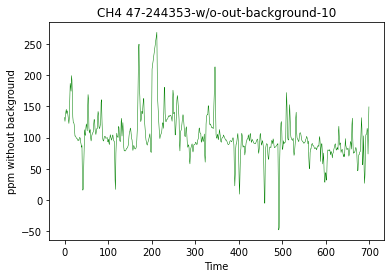

(863, 4)
(859, 4)
Average after removal of background is:  166.18
Median after removal of background is:  125.85
48


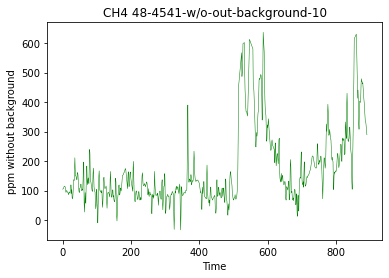

(714, 4)
(712, 4)
Average after removal of background is:  141.11
Median after removal of background is:  91.18
49


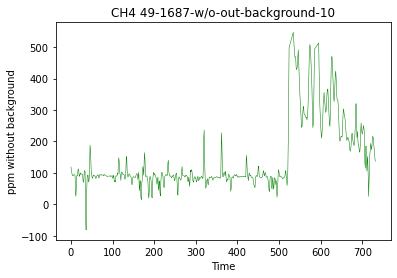

Mean of all milkings is:  215.89720772138477
Mean of all medians is:  149.35484200760564


'\n#Save in a dataframe means for milkings\nmeans_df = pd.DataFrame()\nmilkings = list(mandria_ch4[\'milking_number\'].unique())\nmeans_df[\'milking_number\'] = milkings\nmeans_df[\'means\'] = means\nmeans_df[\'medians\'] = medians\nmeans_df[\'animal\'] = buffaloes\nmeans_df.loc[0, \'final_mean\'] = final_mean\nmeans_df.loc[0, \'final_medians\'] = final_medians\nmeans_df.to_excel("./means_milkings_may.xlsx")\n\n\nprint(means_df.head())\n'

In [7]:
#inspection of milking removal of outliers (first) and background (after) (10 minimum points)

animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
#print(len(animals))
#print(len(mungiture))
    
means = list()
medians = list()
buffaloes = list()
    
for mungitura in mungiture[0:50]:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    #print(milking_ch4.head())
    
    buffalo = milking_ch4.iloc[0,2]
    buffaloes.append(buffalo)
    
    milking_mean = milking_ch4['CH4'].mean()
    #print ("Milking mean is: ", milking_mean)
        
    std = np.std(milking_ch4['CH4'])
    #print('Milking std. deviation is', round(std, 2)) 
    threshold = round(round(std, 2)*3,2)
    #print('treshold is std x3: ', threshold)
    
    positive_outliers = round(milking_mean + threshold, 2)
    negative_outliers = round(milking_mean - threshold, 2)
    #print(positive_outliers, negative_outliers)    
    
    #print(ch4.shape)
    filtered_milking_ch4 = milking_ch4[milking_ch4['CH4'] <= positive_outliers]
    filtered_milking_ch4 = filtered_milking_ch4[filtered_milking_ch4['CH4'] >= negative_outliers]
    
    #print(milking_ch4.shape)
    #print(filtered_milking_ch4.shape)
    
    
    #Calculus of background of each milking with minimum of 5 points
    
    minim = list()    
    ch4 = filtered_milking_ch4    
    #print(ch4.shape)
    for time in range(10):
        minimum = ch4['CH4'].min()
        minim.append(minimum)
        ch4 = ch4[ch4['CH4'] != minimum] #this way we cut that 5 data, but do not remove from all the data
        
    #print(ch4.shape)
    
    minim = pd.Series(minim)
    background = minim.mean()
    #print ("Average minimum background is: ", round(background,2))
    
    ch4_no_back = filtered_milking_ch4
    ch4_no_back['CH4'] = ch4_no_back['CH4'].apply(lambda x: x - background)
    print(ch4_no_back.shape)
    
    #Remove negative data after removal of background
    ch4_no_back_no_neg = ch4_no_back[ch4_no_back['CH4'] > 0]
    #print(ch4_no_back_no_neg.head())
    print(ch4_no_back_no_neg.shape)

    
    #check that the dataframe with which we calculate the minimum is smaller than the original
    #and most important that the original and tha no_back dataframe contains all the data, including all the minimums
    
    #print(ch4.shape)
    #print(milking_ch4.shape)
    
    no_back_mean = ch4_no_back_no_neg['CH4'].mean()
    print("Average after removal of background is: ", round(no_back_mean,2))
    
    means.append(no_back_mean)
    
    no_back_median = ch4_no_back_no_neg['CH4'].median()
    print("Median after removal of background is: ", round(no_back_median,2))
    
    medians.append(no_back_median)
    #print(ch4.shape)
    
    print(str(mungitura))
    
    
    #Plot singole mungiture filtrate per outliers e background
    plt.figure(facecolor='white')
    plt.xlabel('Time')
    plt.ylabel('ppm without background')
    title = "CH4 " + str(mungitura) + "-" + str(buffalo) + "-w/o-out-background-10"
    plt.title(title)
    plt.plot(filtered_milking_ch4['CH4'], linewidth=0.5, color = "green")
    
    #no_back_no_out_mean = filtered_milking_ch4['CH4'].mean()
    #print("Average after removal of background and outliers is: ", no_back_no_out_mean)    
    
    directory = "./plot_bufale/mungiture/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + str(mungitura) + "_filtered_outlier_background_10.png"
    #plt.savefig(file_path, format="png", dpi=200)
    
    plt.show()


#Calcolo media delle medie e delle mediane di tutte le mungiture dopo aver tolto outlier e background

means = pd.Series(means)
final_mean = means.mean()
print("Mean of all milkings is: ", final_mean)



medians = pd.Series(medians)
final_medians = medians.mean()
print("Mean of all medians is: ", final_medians)

'''
#Save in a dataframe means for milkings
means_df = pd.DataFrame()
milkings = list(mandria_ch4['milking_number'].unique())
means_df['milking_number'] = milkings
means_df['means'] = means
means_df['medians'] = medians
means_df['animal'] = buffaloes
means_df.loc[0, 'final_mean'] = final_mean
means_df.loc[0, 'final_medians'] = final_medians
means_df.to_excel("./means_milkings_may.xlsx")


print(means_df.head())
'''